# Streamlining the Customer Grievance Process
### NLP analysis of 2023 retail-banking complaints: text classification + sentiment analysis

**Context.** I'm working as a data scientist for the front office of a large US bank. Every complaint that comes in today gets read and routed by hand, and the text itself is rarely mined for anything beyond that one routing decision.

**Two problems to solve**
1. Daily triage is manual and slow, so complaints sit in a queue before they reach the right product team.
2. The complaint narratives are underused. Nobody is systematically pulling out *why* customers are upset or *how* upset they are.

**Plan**
| Step | What it does | Rubric area |
|---|---|---|
| 1 | Load the data, fix data types, find the date range | Data Understanding & Preprocessing |
| 2 | `preprocessing()` function: lowercase, remove numbers, remove stopwords, remove punctuation, lemmatize | Data Understanding & Preprocessing |
| 3 | Turn the cleaned text into a TF-IDF matrix | Text Feature Engineering |
| 4 | Classify each complaint into its **Department** (the target), evaluate, and show how that automates triage | Complaint Classification |
| 5 | Score every complaint with VADER's `SentimentIntensityAnalyzer` and find what drives the most negative ones | Sentiment Analysis |
| 6 | Fine-tune a transformer (DistilBERT) on the same task and compare it with a transformer sentiment model, in `02_transformer_models.ipynb` | Transformer-based Modeling |
| 7 | Turn the findings into actions for Retail Banking | Business Insights & Strategy |

## 0. Setup

In [1]:
import re
import json
import string
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.decomposition import NMF
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=mpl.MatplotlibDeprecationWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
DATA_PATH = Path("data/banking_complaints_2023.xlsx")
FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

# NLTK resources (only downloads if missing)
for resource, path in [("stopwords", "corpora/stopwords"),
                       ("wordnet", "corpora/wordnet"),
                       ("omw-1.4", "corpora/omw-1.4")]:
    try:
        nltk.data.find(path)
    except LookupError:
        try:
            nltk.data.find(path + ".zip")
        except LookupError:
            nltk.download(resource, quiet=True)

In [2]:
# Plot styling: one consistent, colorblind-checked palette for every chart
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#898781"
SEQ_BLUE = mpl.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGING = mpl.colors.LinearSegmentedColormap.from_list(
    "div_red_blue", ["#b52a2a", "#e34948", "#f0a5a4", "#f0efec", "#9ec5f4", "#2a78d6", "#184f95"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "legend.frameon": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 150,
})

def save(name):
    plt.savefig(FIG_DIR / f"{name}.png")

## 1. Data understanding
### 1.1 Read the data

In [3]:
raw = pd.read_excel(DATA_PATH)
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 7,011   Columns: 9


,Complaint ID,Date Received,Banking Product,Department,Issue ID,Complaint Description,State,ZIP,Bank Response
0,CID76118977,2023-01-01,Checking or savings account,CASA,I_3510635,on XX/XX/XX22 I opened a safe balance account online using my payroll check of over {$600.00} as my account opener. ...,California,92311,Closed with monetary relief
1,CID98703933,2023-01-01,"Credit reporting, credit repair services, or other personal consumer reports",Credit Reports,I_3798538,There is an item from Bank of ABC on my credit report that does not belong to me and must be removed because its a f...,California,91344,Closed with explanation
2,CID52036665,2023-01-01,Checking or savings account,CASA,I_3648593,On XX/XX/XX22 I found out that my account was frozen for no apparent reason. I went to the BOA branch in XXXX XXXX N...,New York,10466,Closed with monetary relief
3,CID62581335,2023-01-01,Credit card or prepaid card,Credit Cards,I_6999080,I've had a credit card for years with Bank of ABC. In XX/XX/XXXX I paid off my balance and because I had it on auto ...,California,92127,Closed with monetary relief
4,CID65731164,2023-01-01,Checking or savings account,CASA,I_3648593,This issue has to do with the way that Bank of ABC does their account linking in their Bill Pay part of their websit...,New Jersey,7946,Closed with explanation


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7011 entries, 0 to 7010
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Complaint ID           7011 non-null   str           
 1   Date Received          7011 non-null   datetime64[us]
 2   Banking Product        7011 non-null   str           
 3   Department             7011 non-null   str           
 4   Issue ID               7011 non-null   str           
 5   Complaint Description  7011 non-null   str           
 6   State                  6984 non-null   str           
 7   ZIP                    6981 non-null   object        
 8   Bank Response          7011 non-null   str           
dtypes: datetime64[us](1), object(1), str(7)
memory usage: 9.0+ MB


In [5]:
# How the ZIP column was actually stored, value by value
print(raw["ZIP"].map(lambda v: type(v).__name__).value_counts())
print("\nExamples of text ZIPs:", raw.loc[raw["ZIP"].map(type) == str, "ZIP"].head(6).tolist())
print("Examples of numeric ZIPs:", raw.loc[raw["ZIP"].map(type) == int, "ZIP"].head(6).tolist())

ZIP
int      4367
str      2614
float      30
Name: count, dtype: int64

Examples of text ZIPs: ['352XX', '224XX', '752XX', '693XX', '088XX', '625XX']
Examples of numeric ZIPs: [92311, 91344, 10466, 92127, 7946, 95608]


### 1.2 Check and correct the data types

What's wrong with the types as loaded:

* **ZIP** is a mixed `object` column holding Python `int`s, `str`s and `NaN`. Excel stored full ZIPs as numbers, which **dropped leading zeros** (`7946` should be `07946`, a New Jersey ZIP). Partially masked ZIPs (`453XX`) came in as text. ZIP is an identifier, not a number, so it becomes a 5-character string.
* **Complaint ID**, **Issue ID** and **Complaint Description** are free text or identifiers, so they become pandas' `string` dtype.
* **Banking Product, Department, State, Bank Response, Issue ID** are low-cardinality labels, so they become `category`. That saves memory and makes the levels explicit.
* **Date Received** already loaded as a datetime. I still run it through `pd.to_datetime(..., errors="coerce")` so the notebook stays safe if the source file ever arrives as text dates.

In [6]:
df = raw.copy()

def clean_zip(z):
    # Return a 5-character ZIP string, restoring leading zeros lost in Excel.
    if pd.isna(z):
        return pd.NA
    z = str(z).strip()
    if z.endswith(".0"):
        z = z[:-2]
    return z.zfill(5) if z.isdigit() else z.upper()

df["Date Received"] = pd.to_datetime(df["Date Received"], errors="coerce")
df["ZIP"] = df["ZIP"].map(clean_zip).astype("string")
for col in ["Complaint ID", "Complaint Description"]:
    df[col] = df[col].astype("string")
for col in ["Banking Product", "Department", "State", "Bank Response", "Issue ID"]:
    df[col] = df[col].astype("category")

dtype_check = pd.DataFrame({"before": raw.dtypes.astype(str), "after": df.dtypes.astype(str)})
dtype_check

,before,after
Complaint ID,str,string
Date Received,datetime64[us],datetime64[us]
Banking Product,str,category
Department,str,category
Issue ID,str,category
Complaint Description,str,string
State,str,category
ZIP,object,string
Bank Response,str,category


In [7]:
print("ZIP examples after cleaning:", df["ZIP"].dropna().sample(8, random_state=1).tolist())
print(f"ZIPs restored with a leading zero: {(df['ZIP'].str.startswith('0')).sum():,}")
print(f"ZIPs partially masked (e.g. 453XX): {df['ZIP'].str.contains('X', na=False).sum():,}")
print(f"\nMemory: {raw.memory_usage(deep=True).sum()/1e6:.1f} MB -> {df.memory_usage(deep=True).sum()/1e6:.1f} MB")

ZIP examples after cleaning: ['06905', '330XX', '53597', '75701', '462XX', '117XX', '08110', '44122']
ZIPs restored with a leading zero: 607
ZIPs partially masked (e.g. 453XX): 2,614

Memory: 9.6 MB -> 8.7 MB


In [8]:
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
print(f"Duplicate Complaint IDs: {df['Complaint ID'].duplicated().sum()}")
print(f"Duplicate complaint texts: {df['Complaint Description'].duplicated().sum()}")
quality

Duplicate Complaint IDs: 0
Duplicate complaint texts: 27


,missing,missing_%,unique_values
Complaint ID,0,0.00,7011
Date Received,0,0.00,288
Banking Product,0,0.00,17
Department,0,0.00,7
Issue ID,0,0.00,130
Complaint Description,0,0.00,6984
State,27,0.39,55
ZIP,30,0.43,3442
Bank Response,0,0.00,6


Data quality is good. The only gaps are **State (27)** and **ZIP (30)**, both under 0.5% and not used for modeling, so I leave them as missing rather than inventing values. Complaint IDs are unique. **27 complaint texts are exact duplicates** of another row (mostly copy-pasted identity-theft letters). I keep them for the descriptive analysis, but I drop them before modeling so the same text can't land in both the training and test sets.

### 1.3 Date range

In [9]:
start, end = df["Date Received"].min(), df["Date Received"].max()
span_days = (end - start).days + 1
print(f"Date range: {start:%A, %B %d, %Y}  to  {end:%A, %B %d, %Y}")
print(f"Span: {span_days} days (~{span_days/30.4:.1f} months), {df['Date Received'].nunique()} distinct receiving days")
print(f"Average volume: {len(df)/span_days:.1f} complaints per calendar day")

Date range: Sunday, January 01, 2023  to  Saturday, October 21, 2023
Span: 294 days (~9.7 months), 288 distinct receiving days
Average volume: 23.8 complaints per calendar day


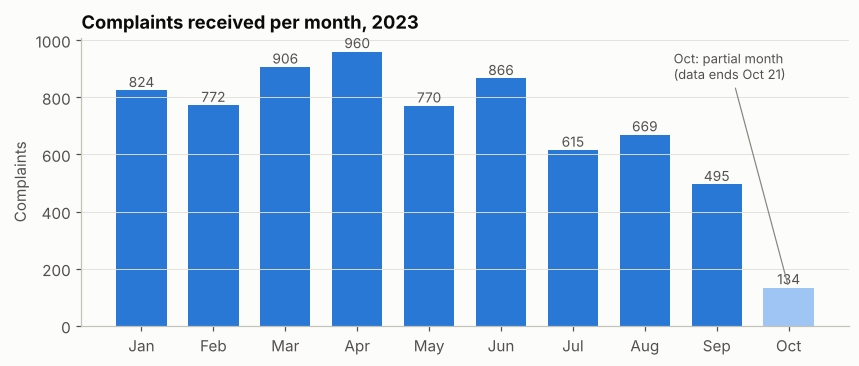

In [10]:
monthly = df.set_index("Date Received").resample("MS").size()
fig, ax = plt.subplots(figsize=(9, 3.4))
colors = [BLUE] * len(monthly)
colors[-1] = "#9ec5f4"  # partial month
ax.bar(monthly.index.strftime("%b"), monthly.values, color=colors, width=0.7)
for i, v in enumerate(monthly.values):
    ax.text(i, v + 12, f"{v:,}", ha="center", fontsize=9, color="#52514e")
ax.set_title("Complaints received per month, 2023")
ax.set_ylabel("Complaints")
ax.grid(axis="x", visible=False)
ax.annotate("Oct: partial month\n(data ends Oct 21)", xy=(len(monthly) - 1, monthly.values[-1]),
            xytext=(len(monthly) - 2.6, monthly.max() * 0.9), fontsize=8.5, color="#52514e",
            arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
save("01_monthly_volume")
plt.show()

The data covers **January 1 to October 21, 2023** (294 days, about 9.7 months, averaging roughly 24 complaints a day). Monthly volume runs roughly 770-960 through June, peaks in **April (960)**, then falls to roughly 500-670 a month from July on. That drop lines up with the product-taxonomy change described in 1.4. October is low only because the data stops on the 21st.

### 1.4 The target: Department

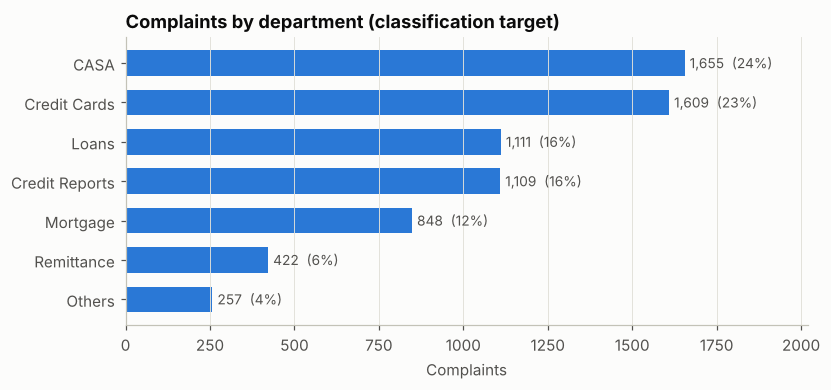

In [11]:
dept_counts = df["Department"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(dept_counts.index[::-1], dept_counts.values[::-1], color=BLUE, height=0.65)
for i, v in enumerate(dept_counts.values[::-1]):
    ax.text(v + 15, i, f"{v:,}  ({v/len(df):.0%})", va="center", fontsize=9, color="#52514e")
ax.set_title("Complaints by department (classification target)")
ax.set_xlabel("Complaints")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, dept_counts.max() * 1.22)
save("02_department_distribution")
plt.show()

Seven departments, moderately imbalanced: **CASA** (current and savings accounts) and **Credit Cards** each take about 23%, while **Others** is under 4%. Because of that imbalance, I judge models on **macro-F1** (every department counts equally), not just accuracy.

In [12]:
# How do Banking Product values relate to Department?
mapping = (df.groupby("Department", observed=True)["Banking Product"]
             .apply(lambda s: sorted(s.unique().tolist())).to_frame("products mapped to this department"))
products_per_dept = df.groupby("Banking Product", observed=True)["Department"].nunique()
print(f"Every Banking Product maps to exactly one Department: {bool((products_per_dept == 1).all())}")
mapping

Every Banking Product maps to exactly one Department: True


,products mapped to this department
Department,
CASA,[Checking or savings account]
Credit Cards,"[Credit card, Credit card or prepaid card, Prepaid card]"
Credit Reports,"[Credit reporting, Credit reporting, credit repair services, or other personal consumer reports]"
Loans,"[Consumer Loan, Debt collection, Payday loan, Payday loan, title loan, or personal loan, Student loan, Vehicle loan ..."
Mortgage,[Mortgage]
Others,"[Bank account or service, Other financial service]"
Remittance,"[Money transfer, virtual currency, or money service, Money transfers]"


In [13]:
product_dates = (df.groupby("Banking Product", observed=True)["Date Received"]
                   .agg(first_seen="min", last_seen="max", complaints="size")
                   .sort_values("last_seen"))
product_dates["first_seen"] = product_dates["first_seen"].dt.date
product_dates["last_seen"] = product_dates["last_seen"].dt.date
product_dates

,first_seen,last_seen,complaints
Banking Product,,,
Other financial service,2023-04-14,2023-04-14,1
Prepaid card,2023-01-13,2023-06-21,17
Money transfers,2023-01-03,2023-06-26,11
Consumer Loan,2023-01-03,2023-07-03,83
Payday loan,2023-01-08,2023-07-03,30
Bank account or service,2023-01-03,2023-07-05,256
Student loan,2023-01-03,2023-07-05,201
Credit card,2023-01-02,2023-07-06,359
Credit reporting,2023-01-01,2023-07-06,550


Two things here shape the modeling:

1. **Banking Product is target leakage.** Each product maps to exactly one department, so a model given the product would score 100% without reading a word. At intake, though, the product field is exactly what the bank is trying to fill in. So the classifier uses **only the complaint text**.
2. **The labels mix an old and a new product taxonomy.** Products like *Bank account or service*, *Credit card*, *Credit reporting* and *Money transfers* (the older names) stop appearing in early **July 2023**. Their replacements carry on to October. The **Others** department is almost entirely the old *Bank account or service* label, which describes the same kinds of problems as **CASA** (*Checking or savings account*). I expect the classifier to confuse those two, and that confusion is largely a labeling issue rather than a modeling one (notebook 02 shows a transformer can recover part of the difference).

count    7011.0
mean      218.0
std       233.0
min         2.0
25%        81.0
50%       148.0
75%       272.0
max      4687.0


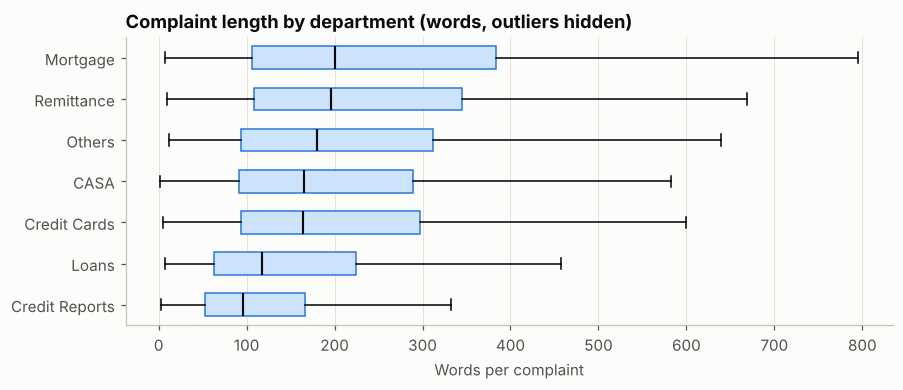

In [14]:
df["word_count"] = df["Complaint Description"].str.split().str.len()
print(df["word_count"].describe().round(0).to_string())

fig, ax = plt.subplots(figsize=(9, 3.4))
order = df.groupby("Department", observed=True)["word_count"].median().sort_values().index
data = [df.loc[df["Department"] == d, "word_count"] for d in order]
bp = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True, widths=0.55,
                medianprops=dict(color="#0b0b0b", lw=1.4))
for patch in bp["boxes"]:
    patch.set(facecolor="#cde2fb", edgecolor=BLUE, lw=1)
ax.set_yticks(range(1, len(order) + 1), order)
ax.set_title("Complaint length by department (words, outliers hidden)")
ax.set_xlabel("Words per complaint")
ax.grid(axis="y", visible=False)
save("03_length_by_department")
plt.show()

Complaints are long-form narratives, not tweets: the median is about **150 words** and a few run past 4,000. **Mortgage** and **Remittance** complaints are the longest (median around 200 words; escrow histories and step-by-step accounts of a scam take a lot of explaining). **Credit Reports** complaints are the shortest (median under 100), since many are short, templated dispute letters. That length matters for both later steps. TF-IDF has plenty of signal to work with. VADER, on the other hand, tends to max out at ±1 on long texts, which I deal with in Section 5.

## 2. Text preprocessing
### 2.1 The `preprocessing` function

The function runs the five required steps **in the specified order**. Each step is its own small helper so it can be tested and inspected on its own.

| # | Step | Implementation notes |
|---|---|---|
| 1 | Lowercase | `str.lower()` |
| 2 | Remove numbers | regex `\d+` → space (dates, dollar amounts, account numbers) |
| 3 | Remove stopwords | NLTK English list plus a few domain words: `abc` (the anonymized bank name, "Bank of ABC") and contractions typed without an apostrophe (`ive`, `dont`). Because punctuation is still present at this step, each token is compared with its surrounding punctuation stripped, so `"it,"` still matches `it`. |
| 4 | Remove punctuation | every punctuation mark (including curly quotes and dashes) → space |
| 5 | Lemmatize | WordNet lemmatizer, applied as a noun and then as a verb, so `payments → payment` and `charged → charge` |

The data provider anonymized names, dates and account numbers as `XXXX` / `XX/XX/XXXX`. Those masks only split into separate tokens once punctuation is gone, so a final tidy-up after step 5 drops mask tokens (`xx`, `xxxx`) and single-character leftovers. That last cleanup isn't one of the five required steps; it's specific to this dataset.

In [15]:
STOP_WORDS = set(stopwords.words("english"))
DOMAIN_STOPWORDS = {
    "abc",                                    # anonymised bank name: "Bank of ABC"
    "ive", "im", "id", "dont", "didnt", "doesnt", "wasnt", "isnt",
    "cant", "wont", "couldnt", "wouldnt", "shouldnt", "havent", "hasnt",
}
STOP_WORDS |= DOMAIN_STOPWORDS

PUNCT = string.punctuation + "“”‘’–—…•"
PUNCT_TABLE = str.maketrans({ch: " " for ch in PUNCT})
MASK_TOKEN = re.compile(r"^x{2,}$")
lemmatizer = WordNetLemmatizer()


def to_lowercase(text):
    return text.lower()

def remove_numbers(text):
    return re.sub(r"\d+", " ", text)

def remove_stopwords(text):
    return " ".join(tok for tok in text.split() if tok.strip(PUNCT) not in STOP_WORDS)

def remove_punctuation(text):
    return re.sub(r"\s+", " ", text.translate(PUNCT_TABLE)).strip()

def lemmatize(text):
    return " ".join(lemmatizer.lemmatize(lemmatizer.lemmatize(tok, pos="n"), pos="v")
                    for tok in text.split())

def drop_masks(text):
    # Dataset-specific tidy-up: remove XXXX anonymisation tokens and 1-character leftovers.
    return " ".join(t for t in text.split() if len(t) > 1 and not MASK_TOKEN.match(t))


def preprocessing(text):
    # Clean one complaint: lowercase -> remove numbers -> remove stopwords
    # -> remove punctuation -> lemmatize (then drop anonymisation masks).
    if not isinstance(text, str):
        return ""
    text = to_lowercase(text)        # 1
    text = remove_numbers(text)      # 2
    text = remove_stopwords(text)    # 3
    text = remove_punctuation(text)  # 4
    text = lemmatize(text)           # 5
    return drop_masks(text)

In [16]:
# Walk one real complaint through each step
sample = df["Complaint Description"].iloc[3][:400]
steps = [("original", lambda t: t), ("1 lowercase", to_lowercase), ("2 no numbers", remove_numbers),
         ("3 no stopwords", remove_stopwords), ("4 no punctuation", remove_punctuation),
         ("5 lemmatized", lemmatize), ("masks dropped", drop_masks)]
current = sample
for name, fn in steps:
    current = fn(current)
    print(f"[{name}]\n{current}\n")

[original]
I've had a credit card for years with Bank of ABC. In XX/XX/XXXX I paid off my balance and because I had it on auto pay, it continued to pay and I ended up with a credit balance. They notified me repeatedly since they didn't want the credit balance so I turned off the auto payment and they sent me a check. 

Then in XX/XX/XXXX I did another balance transfer. I forgot I had turned off the auto paym

[1 lowercase]
i've had a credit card for years with bank of abc. in xx/xx/xxxx i paid off my balance and because i had it on auto pay, it continued to pay and i ended up with a credit balance. they notified me repeatedly since they didn't want the credit balance so i turned off the auto payment and they sent me a check. 

then in xx/xx/xxxx i did another balance transfer. i forgot i had turned off the auto paym

[2 no numbers]
i've had a credit card for years with bank of abc. in xx/xx/xxxx i paid off my balance and because i had it on auto pay, it continued to pay and i ended up 

[5 lemmatized]
credit card year bank xx xx xxxx pay balance auto pay continue pay end credit balance notify repeatedly since want credit balance turn auto payment send check xx xx xxxx another balance transfer forget turn auto paym

[masks dropped]
credit card year bank pay balance auto pay continue pay end credit balance notify repeatedly since want credit balance turn auto payment send check another balance transfer forget turn auto paym



### 2.2 Clean the `Complaint Description` column

In [17]:
t0 = time.perf_counter()
df["clean_text"] = df["Complaint Description"].astype(str).map(preprocessing)
print(f"Cleaned {len(df):,} complaints in {time.perf_counter() - t0:.1f}s")

df["clean_word_count"] = df["clean_text"].str.split().str.len()
print(f"Average words per complaint: {df['word_count'].mean():.0f} raw -> {df['clean_word_count'].mean():.0f} cleaned "
      f"({1 - df['clean_word_count'].sum()/df['word_count'].sum():.0%} reduction)")
print(f"Empty after cleaning: {(df['clean_word_count'] == 0).sum()}")
df[["Complaint Description", "clean_text"]].head(3)

Cleaned 7,011 complaints in 4.6s
Average words per complaint: 218 raw -> 93 cleaned (57% reduction)
Empty after cleaning: 0


,Complaint Description,clean_text
0,on XX/XX/XX22 I opened a safe balance account online using my payroll check of over {$600.00} as my account opener. ...,open safe balance account online use payroll check account opener attempt login app receive account lock contact cus...
1,There is an item from Bank of ABC on my credit report that does not belong to me and must be removed because its a f...,item bank credit report belong must remove fraud item always return back confirm account belong proof need item remo...
2,On XX/XX/XX22 I found out that my account was frozen for no apparent reason. I went to the BOA branch in XXXX XXXX N...,find account freeze apparent reason go boa branch ny explain whats go make call beleived call fix income boa hold fu...


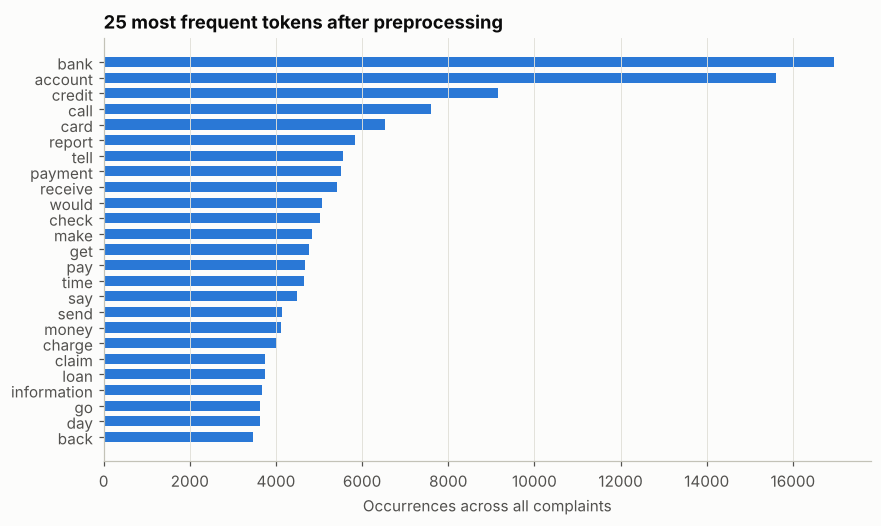

Vocabulary size after cleaning: 11,837 distinct tokens


In [18]:
from collections import Counter
token_counts = Counter(tok for doc in df["clean_text"] for tok in doc.split())
top_tokens = pd.Series(dict(token_counts.most_common(25)))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_tokens.index[::-1], top_tokens.values[::-1], color=BLUE, height=0.65)
ax.set_title("25 most frequent tokens after preprocessing")
ax.set_xlabel("Occurrences across all complaints")
ax.grid(axis="y", visible=False)
save("04_top_tokens")
plt.show()
print(f"Vocabulary size after cleaning: {len(token_counts):,} distinct tokens")

The cleaned vocabulary is all banking language: *account, credit, payment, report, card, loan, call, information, debt*. None of the high-frequency stopword, number or punctuation noise survived. The most frequent words are generic, which is why the next step uses **TF-IDF**: it down-weights words that appear in almost every complaint and up-weights the ones that set a department apart.

## 3. TF-IDF feature engineering

**Split first, then vectorize.** I hold out a stratified 20% test set *before* fitting TF-IDF, so test-set vocabulary and document frequencies never leak into training. Exact duplicate texts are removed first (Section 1.2).

Vectorizer settings, and why:
* `ngram_range=(1, 2)`: bigrams capture phrases that carry meaning on their own, like *credit report*, *late fee*, *identity theft*, *escrow account*.
* `min_df=3`: ignore terms in fewer than 3 complaints (typos, leftover names).
* `max_df=0.9`: ignore terms in more than 90% of complaints (no discriminating value).
* `sublinear_tf=True`: use 1 + log(tf), so a word repeated 20 times in a long rant doesn't swamp everything else.

In [19]:
model_df = (df.drop_duplicates(subset="Complaint Description", keep="first")
              .loc[lambda d: d["clean_word_count"] > 0]
              .reset_index(drop=True))
X_text, y = model_df["clean_text"], model_df["Department"].astype(str)

X_train_text, X_test_text, y_train, y_test, id_train, id_test = train_test_split(
    X_text, y, model_df["Complaint ID"], test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Modeling rows: {len(model_df):,}  ->  train {len(X_train_text):,} / test {len(X_test_text):,}")

# Save the split so the transformer notebook trains and tests on exactly the same complaints
pd.concat([pd.DataFrame({"Complaint ID": id_train, "split": "train"}),
           pd.DataFrame({"Complaint ID": id_test, "split": "test"})]).to_csv(OUT_DIR / "split_ids.csv", index=False)

Modeling rows: 6,984  ->  train 5,587 / test 1,397


In [20]:
TFIDF_PARAMS = dict(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
tfidf = TfidfVectorizer(**TFIDF_PARAMS)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

n_docs, n_terms = X_train.shape
print(f"TF-IDF train matrix: {n_docs:,} complaints x {n_terms:,} features")
print(f"TF-IDF test matrix:  {X_test.shape[0]:,} complaints x {X_test.shape[1]:,} features")
print(f"Non-zero entries: {X_train.nnz:,}  -> sparsity {1 - X_train.nnz/(n_docs*n_terms):.2%}")
vocab = tfidf.get_feature_names_out()
print(f"Unigrams: {sum(' ' not in v for v in vocab):,}   Bigrams: {sum(' ' in v for v in vocab):,}")

TF-IDF train matrix: 5,587 complaints x 36,092 features
TF-IDF test matrix:  1,397 complaints x 36,092 features
Non-zero entries: 583,083  -> sparsity 99.71%
Unigrams: 4,653   Bigrams: 31,439


In [21]:
# Peek at the matrix: the highest-weighted terms for one complaint
row = 0
weights = pd.Series(X_train[row].toarray().ravel(), index=vocab)
print("Department:", y_train.iloc[row])
print("Cleaned text (start):", X_train_text.iloc[row][:200], "...\n")
weights[weights > 0].sort_values(ascending=False).head(10).round(3).to_frame("tf-idf weight")

Department: Credit Reports
Cleaned text (start): dispute account reach time fail account report inaccurately incorrectly credit report tell congress pass coronavirus aid relief economic security act care act minimize impact covid pandemic particular ...



,tf-idf weight
care act,0.197
covid pandemic,0.185
pandemic,0.175
covid,0.139
account report,0.139
consumer affect,0.134
affect covid,0.134
coronavirus,0.134
economic security,0.134
consumer see,0.134


In [22]:
# Which terms set each department apart? (mean TF-IDF inside the department minus mean everywhere else)
dense_means = {}
for dept in sorted(y_train.unique()):
    in_dept = (y_train == dept).values
    dense_means[dept] = (np.asarray(X_train[in_dept].mean(axis=0)).ravel()
                         - np.asarray(X_train[~in_dept].mean(axis=0)).ravel())
distinctive = pd.DataFrame({dept: vocab[np.argsort(-scores)[:8]] for dept, scores in dense_means.items()})
distinctive.index = [f"#{i+1}" for i in range(8)]
distinctive.T

,#1,#2,#3,#4,#5,#6,#7,#8
CASA,check,bank,account,deposit,check account,money,fund,close
Credit Cards,card,credit card,credit,charge,bank credit,purchase,use,statement
Credit Reports,report,credit report,credit,remove,inquiry,equifax,dispute,information
Loans,debt,collection,loan,owe,company,pay,collect,navient
Mortgage,mortgage,loan,modification,home,foreclosure,payment,property,escrow
Others,check,bank america,america,fee,deposit,fargo,well fargo,account
Remittance,transfer,money,wire,scam,scammed,scammer,transaction,send


Even before any model, the TF-IDF space separates most departments cleanly: **Mortgage** is *modification, foreclosure, escrow*; **Credit Reports** is *credit report, remove, inquiry, Equifax, dispute*; **Remittance** is *transfer, wire, scam/scammer*; **Loans** is *debt, collection, owe, Navient*. **Others** is the odd one out. Its distinctive terms are CASA vocabulary (*check, deposit, account, fee*) plus the names of *other* banks (*Bank of America, Wells Fargo*). That fits the reading that Others is a legacy catch-all for deposit-account complaints, which means the model will have a hard time telling it apart from CASA.

## 4. Complaint classification: predicting the Department

**Target:** `Department` (7 classes). **Features:** the TF-IDF matrix from Section 3. Nothing else, so there's no leakage from Banking Product.

**Workflow**
1. Compare four models with **5-fold stratified cross-validation on the training set only**. Each fold re-fits TF-IDF inside a `Pipeline`, so no fold sees its validation text.
2. Tune the best model with `GridSearchCV`.
3. Evaluate **once** on the untouched test set.
4. Analyze the errors and turn prediction confidence into a triage rule.

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Complement Naive Bayes": ComplementNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(C=10, class_weight="balanced", max_iter=3000),
    "Linear SVM": LinearSVC(C=0.5, class_weight="balanced"),
}
cv_rows = []
for name, clf in candidates.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(**TFIDF_PARAMS)), ("clf", clf)])
    t0 = time.perf_counter()
    res = cross_validate(pipe, X_train_text, y_train, cv=cv, n_jobs=-1,
                         scoring={"accuracy": "accuracy", "macro_f1": "f1_macro", "weighted_f1": "f1_weighted"})
    cv_rows.append({"model": name,
                    "accuracy": res["test_accuracy"].mean(),
                    "macro_F1": res["test_macro_f1"].mean(),
                    "macro_F1_std": res["test_macro_f1"].std(),
                    "weighted_F1": res["test_weighted_f1"].mean(),
                    "seconds": time.perf_counter() - t0})
cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("macro_F1", ascending=False)
cv_results.round(3)

,accuracy,macro_F1,macro_F1_std,weighted_F1,seconds
model,,,,,
Logistic Regression,0.772,0.731,0.028,0.769,7.884
Linear SVM,0.774,0.729,0.022,0.770,2.808
Complement Naive Bayes,0.735,0.611,0.013,0.715,2.598
Baseline (most frequent),0.236,0.055,0.000,0.090,4.048


In [24]:
best_name = cv_results.drop("Baseline (most frequent)").index[0]
print("Best model in cross-validation:", best_name)

if best_name == "Linear SVM":
    base_clf, grid = LinearSVC(class_weight="balanced"), {"clf__C": [0.1, 0.25, 0.5, 1.0]}
elif best_name == "Logistic Regression":
    base_clf, grid = LogisticRegression(class_weight="balanced", max_iter=3000), {"clf__C": [3, 10, 30]}
else:
    base_clf, grid = ComplementNB(), {"clf__alpha": [0.1, 0.3, 1.0]}
grid["tfidf__ngram_range"] = [(1, 1), (1, 2)]

search = GridSearchCV(Pipeline([("tfidf", TfidfVectorizer(**TFIDF_PARAMS)), ("clf", base_clf)]),
                      grid, cv=cv, scoring="f1_macro", n_jobs=-1)
search.fit(X_train_text, y_train)
print("Best params:", search.best_params_)
print(f"Best CV macro-F1: {search.best_score_:.3f}")
pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]] \
  .sort_values("mean_test_score", ascending=False).round(3)

Best model in cross-validation: Logistic Regression


Best params: {'clf__C': 3, 'tfidf__ngram_range': (1, 2)}
Best CV macro-F1: 0.736


,params,mean_test_score,std_test_score
1,"{'clf__C': 3, 'tfidf__ngram_range': (1, 2)}",0.736,0.023
3,"{'clf__C': 10, 'tfidf__ngram_range': (1, 2)}",0.731,0.028
5,"{'clf__C': 30, 'tfidf__ngram_range': (1, 2)}",0.729,0.027
0,"{'clf__C': 3, 'tfidf__ngram_range': (1, 1)}",0.724,0.023
2,"{'clf__C': 10, 'tfidf__ngram_range': (1, 1)}",0.716,0.018
4,"{'clf__C': 30, 'tfidf__ngram_range': (1, 1)}",0.703,0.016


In [25]:
final_model = search.best_estimator_
y_pred = final_model.predict(X_test_text)

test_acc = accuracy_score(y_test, y_pred)
test_macro = f1_score(y_test, y_pred, average="macro")
test_weighted = f1_score(y_test, y_pred, average="weighted")
print(f"TEST accuracy:    {test_acc:.3f}")
print(f"TEST macro-F1:    {test_macro:.3f}")
print(f"TEST weighted-F1: {test_weighted:.3f}\n")
print(classification_report(y_test, y_pred, digits=3))

TEST accuracy:    0.788
TEST macro-F1:    0.734
TEST weighted-F1: 0.784

                precision    recall  f1-score   support

          CASA      0.742     0.825     0.781       331
  Credit Cards      0.808     0.776     0.792       321
Credit Reports      0.799     0.744     0.771       219
         Loans      0.833     0.837     0.835       221
      Mortgage      0.874     0.941     0.907       170
        Others      0.625     0.294     0.400        51
    Remittance      0.636     0.667     0.651        84

      accuracy                          0.788      1397
     macro avg      0.760     0.726     0.734      1397
  weighted avg      0.786     0.788     0.784      1397



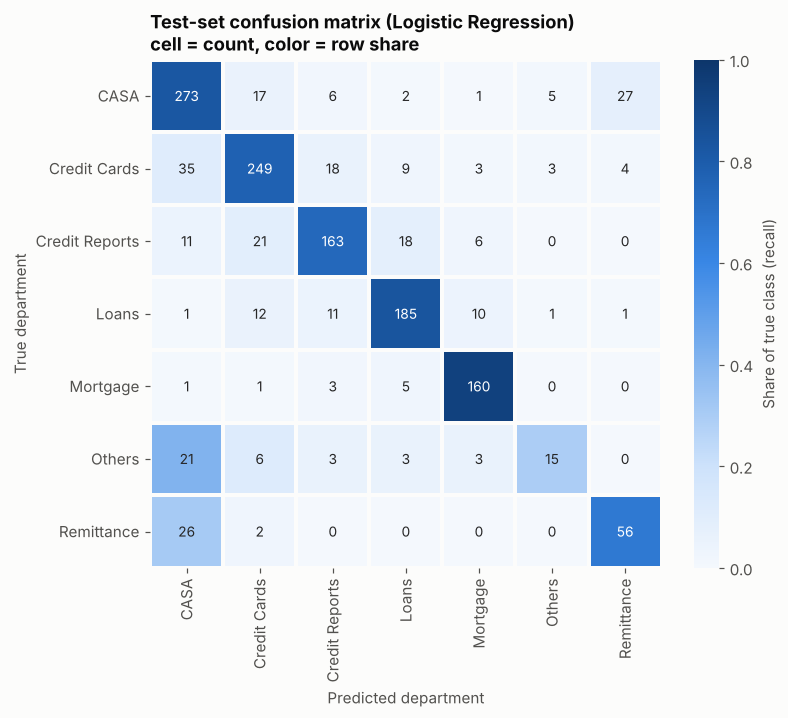

In [26]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap=SEQ_BLUE, vmin=0, vmax=1, cbar_kws={"label": "Share of true class (recall)"},
            xticklabels=labels, yticklabels=labels, linewidths=1.5, linecolor="#fcfcfb", ax=ax,
            annot_kws={"fontsize": 9})
ax.set_xlabel("Predicted department")
ax.set_ylabel("True department")
ax.set_title(f"Test-set confusion matrix ({best_name})\ncell = count, color = row share")
ax.grid(False)
save("05_confusion_matrix")
plt.show()

In [27]:
errors = pd.DataFrame({"true": y_test.values, "pred": y_pred})
errors = errors[errors["true"] != errors["pred"]]
print(f"Misclassified: {len(errors)} of {len(y_test)} test complaints\n")
print("Most common confusions:")
print(errors.value_counts().head(6).to_string())

# Sensitivity check: what if the legacy 'Others' label were folded into CASA, which it duplicates?
merge = lambda s: pd.Series(s).replace({"Others": "CASA"})
print(f"\nAccuracy if Others and CASA are treated as one queue: {accuracy_score(merge(y_test), merge(y_pred)):.3f} "
      f"(vs {test_acc:.3f})")

Misclassified: 296 of 1397 test complaints

Most common confusions:
true            pred        
Credit Cards    CASA            35
CASA            Remittance      27
Remittance      CASA            26
Credit Reports  Credit Cards    21
Others          CASA            21
Credit Reports  Loans           18

Accuracy if Others and CASA are treated as one queue: 0.807 (vs 0.788)


In [28]:
# What the model learned: highest-weight terms per department
clf = final_model.named_steps["clf"]
feat = final_model.named_steps["tfidf"].get_feature_names_out()
top_terms = pd.DataFrame({cls: feat[np.argsort(-clf.coef_[i])[:10]] for i, cls in enumerate(clf.classes_)})
top_terms.index = [f"#{i+1}" for i in range(10)]
top_terms.T

,#1,#2,#3,#4,#5,#6,#7,#8,#9,#10
CASA,bank,account,check,deposit,check account,debit,fund,claim,close,debit card
Credit Cards,card,credit card,credit,charge,edd,balance,benefit,purchase,visa,reward
Credit Reports,report,equifax,credit,transunion,remove,experian,inquiry,dispute,score,credit report
Loans,debt,collection,loan,navient,owe,threaten,credit report,company,collect,vehicle
Mortgage,mortgage,loan,home,modification,escrow,foreclosure,property,lender,refinance,payment
Others,bank america,america,pnc,check,chase,fee,fargo,well fargo,overdraft,account
Remittance,transfer,money,wire,scam,scammed,transaction,scammer,send,recipient,bank


### 4.1 From classifier to triage rule

A classifier doesn't have to route *everything* to be useful. If it is confident, the complaint goes straight to the department queue. If not, a person looks at it. To get reliable confidence scores I wrap the tuned model in `CalibratedClassifierCV` (fit on the training set only), then check on the test set how much of the volume could be auto-routed at different confidence thresholds, and how accurate those auto-routed complaints are.

In [29]:
calibrated = CalibratedClassifierCV(final_model, cv=5, method="sigmoid")
calibrated.fit(X_train_text, y_train)
proba = calibrated.predict_proba(X_test_text)
conf = proba.max(axis=1)
cal_pred = calibrated.classes_[proba.argmax(axis=1)]

rows = []
for t in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    mask = conf >= t
    rows.append({"confidence ≥": t, "auto-routed share": mask.mean(),
                 "accuracy on auto-routed": accuracy_score(y_test[mask], cal_pred[mask]) if mask.any() else np.nan,
                 "sent to manual review": (~mask).sum()})
triage = pd.DataFrame(rows).set_index("confidence ≥")
triage.style.format({"auto-routed share": "{:.1%}", "accuracy on auto-routed": "{:.1%}"})

,auto-routed share,accuracy on auto-routed,sent to manual review
confidence ≥,,,
0.000000,100.0%,78.3%,0
0.500000,85.1%,83.3%,208
0.600000,67.9%,87.9%,449
0.700000,50.2%,90.9%,696
0.800000,27.8%,95.1%,1008
0.900000,3.4%,97.9%,1349


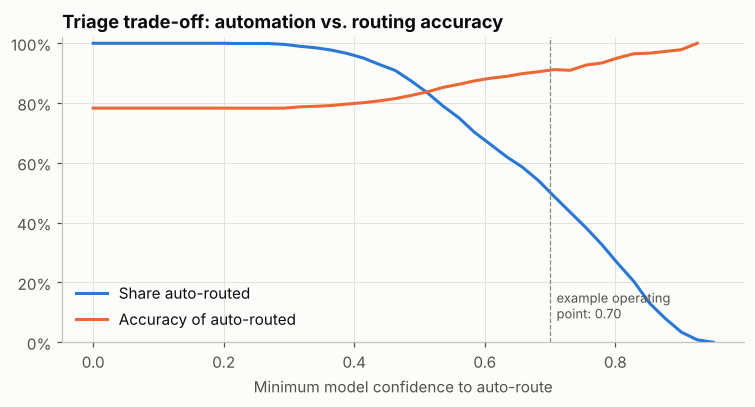

('MANUAL REVIEW', 0.694) <- Someone opened a credit card in my name and the bank refuses to close it or remove the charges.
('Mortgage', 0.79) <- My escrow payment doubled and the servicer won't explain the shortage calculation.
('MANUAL REVIEW', 0.484) <- The money I sent through Zelle never arrived and the bank says they can't recover it.
('MANUAL REVIEW', 0.456) <- I was charged a fee and nobody will call me back.


In [30]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ts = np.linspace(0, 0.95, 40)
cov = [(conf >= t).mean() for t in ts]
acc = [accuracy_score(y_test[conf >= t], cal_pred[conf >= t]) if (conf >= t).any() else np.nan for t in ts]
ax.plot(ts, cov, color=BLUE, lw=2, label="Share auto-routed")
ax.plot(ts, acc, color=ORANGE, lw=2, label="Accuracy of auto-routed")
ax.axvline(0.7, color=GRAY, lw=0.8, ls="--")
ax.text(0.71, 0.08, "example operating\npoint: 0.70", fontsize=8.5, color="#52514e")
ax.set_ylim(0, 1.02)
ax.set_xlabel("Minimum model confidence to auto-route")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_title("Triage trade-off: automation vs. routing accuracy")
ax.legend(loc="lower left")
save("06_triage_tradeoff")
plt.show()

def route_complaint(text, threshold=0.7):
    # Route a raw complaint: returns (department or 'MANUAL REVIEW', confidence).
    p = calibrated.predict_proba([preprocessing(text)])[0]
    i = p.argmax()
    return (calibrated.classes_[i] if p[i] >= threshold else "MANUAL REVIEW", round(float(p[i]), 3))

for txt in ["Someone opened a credit card in my name and the bank refuses to close it or remove the charges.",
            "My escrow payment doubled and the servicer won't explain the shortage calculation.",
            "The money I sent through Zelle never arrived and the bank says they can't recover it.",
            "I was charged a fee and nobody will call me back."]:
    print(route_complaint(txt), "<-", txt)

In [31]:
tfidf_metrics = {
    "model": f"TF-IDF + {best_name}",
    "best_params": {k: str(v) for k, v in search.best_params_.items()},
    "cv_macro_f1": round(float(search.best_score_), 4),
    "test_accuracy": round(float(test_acc), 4),
    "test_macro_f1": round(float(test_macro), 4),
    "test_weighted_f1": round(float(test_weighted), 4),
    "per_class_f1": {k: round(v["f1-score"], 4) for k, v in classification_report(y_test, y_pred, output_dict=True).items()
                     if k in labels},
}
(OUT_DIR / "tfidf_metrics.json").write_text(json.dumps(tfidf_metrics, indent=2))
tfidf_metrics

{'model': 'TF-IDF + Logistic Regression',
 'best_params': {'clf__C': '3', 'tfidf__ngram_range': '(1, 2)'},
 'cv_macro_f1': 0.7361,
 'test_accuracy': 0.7881,
 'test_macro_f1': 0.7338,
 'test_weighted_f1': 0.784,
 'per_class_f1': {'CASA': 0.7811,
  'Credit Cards': 0.7917,
  'Credit Reports': 0.7707,
  'Loans': 0.8352,
  'Mortgage': 0.9065,
  'Others': 0.4,
  'Remittance': 0.6512}}

### 4.2 Classification results

* **Logistic Regression and Linear SVM are essentially tied** in cross-validation (macro-F1 about 0.73). Complement Naive Bayes is clearly behind (0.61), and every real model beats the majority-class baseline by a wide margin (23.6% accuracy). Logistic Regression won narrowly. Tuning settled on `C=3` with unigrams + bigrams. Bigrams added about 1-3 points of macro-F1 over unigrams alone.
* **Held-out test set: 78.8% accuracy, macro-F1 0.734, weighted-F1 0.784.** The CV and test scores are almost identical (0.736 vs 0.734), so the model isn't overfitting.
* **Strong departments:** Mortgage (F1 0.91) and Loans (0.84) use vocabulary nobody else uses (*escrow, foreclosure, collector, Navient*).
* **Weak departments, and why:**
  * **Others (F1 0.40, recall 29%)**: 21 of its 51 test complaints were predicted as CASA. As shown in 1.4, Others is a legacy label for the same deposit-account problems, so a bag-of-words model has little to separate them on. (Fine-tuned DistilBERT in notebook 02 lifts Others to F1 0.68, so the overlap is large but not total.) Treating Others and CASA as one queue raises accuracy to **80.7%**.
  * **Remittance ↔ CASA** (27 + 26 errors): Zelle and wire-transfer complaints are also checking-account complaints. Money leaves the checking account, so both labels are defensible.
  * **Credit Cards → CASA** (35 errors): mostly debit-card versus credit-card fraud disputes, which read almost the same.
* **Triage value:** with calibrated probabilities, auto-routing every complaint the model is at least **70%** confident about handles **about half of all complaints at 91% accuracy**. At 60% confidence it handles **68% at 88% accuracy**. The rest go to a person. That roughly halves the manual triage workload without routing more than about 1 in 10 auto-routed complaints to the wrong team, and a misrouted complaint can still be passed along.

## 5. Sentiment analysis with VADER

`SentimentIntensityAnalyzer` scores text with a lexicon of about 7,500 words, each rated from -4 to +4, plus rules for **negation** ("not good"), **intensifiers** ("very"), **ALL CAPS**, **punctuation** ("!!!") and **contrast** ("but"). It returns `neg`, `neu` and `pos` proportions, plus a `compound` score normalized to [-1, +1].

**VADER gets the raw text, not the preprocessed text.** The preprocessing step removes stopwords like *not, no, never, but, very*, which are exactly what VADER's rules depend on, and lowercasing removes the ALL-CAPS signal. The only thing I strip is the `XXXX` anonymization masks.

In [32]:
analyzer = SentimentIntensityAnalyzer()

def vader_text(text):
    # Light cleanup only: drop XXXX masks, keep case, punctuation and negations.
    text = re.sub(r"\bX{2,}(/X{2,})*\b", " ", str(text))
    text = re.sub(r"[{}]", "", text)
    return re.sub(r"\s+", " ", text).strip()

demo = "The bank did not resolve my dispute and I am NOT happy!!!"
print("Raw text:      ", analyzer.polarity_scores(demo))
print("Cleaned text:  ", analyzer.polarity_scores(preprocessing(demo)), " <-", repr(preprocessing(demo)))

Raw text:       {'neg': 0.35, 'neu': 0.52, 'pos': 0.13, 'compound': -0.5859}
Cleaned text:   {'neg': 0.27, 'neu': 0.1, 'pos': 0.63, 'compound': 0.5574}  <- 'bank resolve dispute happy'


In [33]:
t0 = time.perf_counter()
df["vader_input"] = df["Complaint Description"].map(vader_text)
scores = pd.DataFrame([analyzer.polarity_scores(t) for t in df["vader_input"]], index=df.index)
df[["vader_neg", "vader_neu", "vader_pos", "vader_compound"]] = scores[["neg", "neu", "pos", "compound"]].values
print(f"Scored {len(df):,} complaints in {time.perf_counter() - t0:.1f}s")

def label(c):
    return "Positive" if c >= 0.05 else ("Negative" if c <= -0.05 else "Neutral")
df["vader_label"] = df["vader_compound"].map(label)
print(df["vader_label"].value_counts(normalize=True).round(3).to_string())
df[["vader_neg", "vader_neu", "vader_pos", "vader_compound"]].describe().round(3)

Scored 7,011 complaints in 12.5s
vader_label
Negative    0.545
Positive    0.410
Neutral     0.045


,vader_neg,vader_neu,vader_pos,vader_compound
count,7011.000,7011.000,7011.000,7011.000
mean,0.078,0.853,0.069,-0.118
std,0.056,0.071,0.051,0.696
min,0.000,0.299,0.000,-1.000
25%,0.042,0.814,0.034,-0.812
50%,0.070,0.859,0.061,-0.226
75%,0.103,0.900,0.095,0.572
max,0.700,1.000,0.688,0.999


### 5.1 A sanity check: why are so many complaints "positive"?

Every row in this dataset is a complaint, yet out-of-the-box VADER calls a large share of them **positive**. Before relying on the scores, it's worth finding out why. VADER was built for social media, and its lexicon treats a number of everyday **banking words** as positive sentiment.

In [34]:
lex = analyzer.lexicon
doc_freq = Counter()
for t in df["vader_input"]:
    doc_freq.update({w for w in re.findall(r"[a-z']+", t.lower()) if w in lex})
lex_hits = pd.DataFrame([(w, n, lex[w]) for w, n in doc_freq.most_common(40)],
                        columns=["word", "complaints containing it", "VADER valence"])
lex_hits[lex_hits["VADER valence"] > 0].head(15).reset_index(drop=True)

,word,complaints containing it,VADER valence
0,credit,3183,1.6
1,number,1452,0.3
2,help,1250,1.7
3,please,1015,1.3
4,like,906,1.5
5,want,818,0.3
6,well,760,1.1
7,interest,568,2.0
8,matter,530,0.1
9,security,476,1.4


*Credit* (+1.6) appears in **3,000+ complaints**, but in banking it's a product name, not praise. *Interest* (+2.0), *security*, *agreement*, *original*, *party* (as in "third party"), *approved* and *fair* (as in the Fair Credit Reporting Act) are the same story. There's also a group of **request formulas**, like *please help*, *I would like*, *thank you for your help*, which are politeness inside a complaint, not satisfaction.

**Domain adjustment.** I keep the same `SentimentIntensityAnalyzer` and set those words to neutral (valence 0) in its lexicon. Genuinely emotional words (*fraud, scam, refuse, unfair, terrible*) are left alone. This is the usual way to adapt a lexicon model to a domain, and the list is short and explicit so it can be audited.

In [35]:
BANKING_JARGON = ["credit", "credited", "creditor", "interest", "security", "secure", "original", "party",
                  "agreement", "agreed", "agree", "approved", "approval", "legal", "number", "fair", "clear",
                  "cleared", "alert", "consent", "matter", "reach", "reached", "allow", "allowed", "save",
                  "savings", "share", "fund", "funds", "benefit", "reward", "rewards", "free", "bonus",
                  "cash", "grant", "granted", "growth", "capital", "trust", "trusted", "worth", "wealth"]
REQUEST_FORMULAS = ["please", "thank", "thanks", "help", "helped", "helping", "like", "well", "sure",
                    "hope", "hoping", "appreciate", "appreciated", "kindly", "assist", "assistance",
                    "resolve", "resolved", "support", "want", "assured"]
neutralise = sorted({w for w in BANKING_JARGON + REQUEST_FORMULAS if w in lex})
print(f"Neutralising {len(neutralise)} lexicon entries:\n{', '.join(neutralise)}")

analyzer_adj = SentimentIntensityAnalyzer()
analyzer_adj.lexicon.update({w: 0.0 for w in neutralise})

adj = pd.DataFrame([analyzer_adj.polarity_scores(t) for t in df["vader_input"]], index=df.index)
df[["sent_neg", "sent_neu", "sent_pos", "sent_compound"]] = adj[["neg", "neu", "pos", "compound"]].values
df["sent_label"] = df["sent_compound"].map(label)

compare = pd.DataFrame({"Out-of-the-box VADER": df["vader_label"].value_counts(normalize=True),
                        "Domain-adjusted VADER": df["sent_label"].value_counts(normalize=True)}
                       ).reindex(["Negative", "Neutral", "Positive"])
compare.style.format("{:.1%}")

Neutralising 56 lexicon entries:
agree, agreed, agreement, alert, allow, appreciate, appreciated, approval, approved, assured, benefit, bonus, clear, cleared, consent, credit, credited, creditor, fair, free, grant, granted, growth, help, helping, hope, hoping, interest, kindly, legal, like, matter, number, original, party, please, reach, reached, resolve, resolved, reward, rewards, save, secure, security, share, support, sure, thank, thanks, trust, trusted, want, wealth, well, worth


,Out-of-the-box VADER,Domain-adjusted VADER
Negative,54.5%,80.0%
Neutral,4.5%,7.8%
Positive,41.0%,12.2%


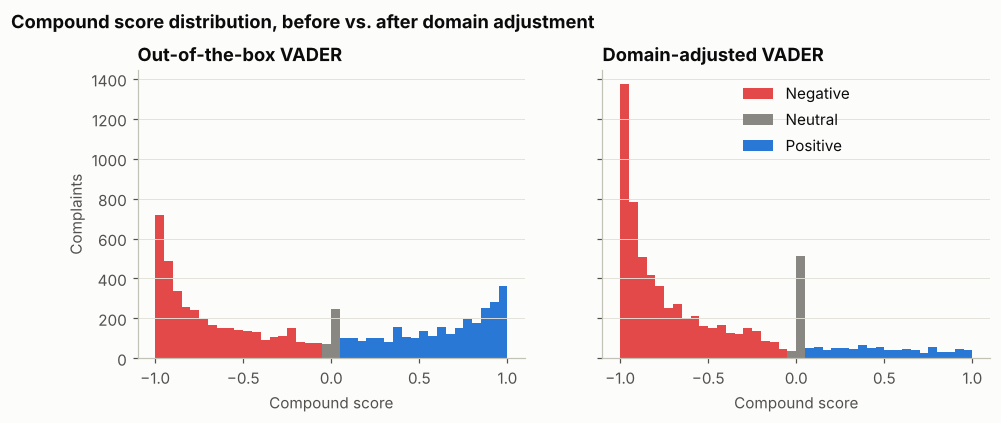

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
bins = np.linspace(-1, 1, 41)
for ax, col, title in [(axes[0], "vader_compound", "Out-of-the-box VADER"),
                       (axes[1], "sent_compound", "Domain-adjusted VADER")]:
    vals = df[col]
    ax.hist(vals[vals <= -0.05], bins=bins, color=RED, label="Negative")
    ax.hist(vals[(vals > -0.05) & (vals < 0.05)], bins=bins, color=GRAY, label="Neutral")
    ax.hist(vals[vals >= 0.05], bins=bins, color=BLUE, label="Positive")
    ax.set_title(title)
    ax.set_xlabel("Compound score")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Complaints")
axes[1].legend(loc="upper center")
fig.suptitle("Compound score distribution, before vs. after domain adjustment", x=0.01, ha="left",
             fontweight="bold", fontsize=12, y=1.04)
save("07_compound_distribution")
plt.show()

In [37]:
pd.set_option("display.max_colwidth", 400)
show = lambda d: d[["Department", "sent_compound", "vader_compound", "Complaint Description"]].assign(
    **{"Complaint Description": d["Complaint Description"].str.slice(0, 380) + " ..."})
print("Most negative complaints (domain-adjusted):")
display(show(df.nsmallest(2, "sent_compound")))
print("Complaints that still score most positive (a known limitation):")
display(show(df.nlargest(2, "sent_compound")))
pd.set_option("display.max_colwidth", 120)

Most negative complaints (domain-adjusted):


,Department,sent_compound,vader_compound,Complaint Description
2261,Mortgage,-0.9997,-0.9996,Subject of the complaint : A notice dated XX/XX/XXXX from Bank of ABC was mailed to XXXX XXXX stating that the interest rate of our mortgage loan that they own and service will increase by 0.750 % for 272 months and a final balloon payment of {$250000.00}. We adamantly state again that this mortgage loan modification issued by XXXX XXXX XXXX in XXXX is fraudulent. The original ...
2499,Remittance,-0.9995,-0.9984,"To whom it may concern, Bank of ABC not Investigating Fraud. \n\nI am writing to bring to your attention and ask for any help that you can provide to expose the pervasive fraudulent activities affecting BOA customers including myself. I am also respectfully asking for help resolving my fraudulent claim ( {$8000.00} ) which BOA has denied with little to no Investigation. From my p ..."


Complaints that still score most positive (a known limitation):


,Department,sent_compound,vader_compound,Complaint Description
6603,Loans,0.9946,0.998,I would like to start off by first saying that it has been a long XXXX months. I have been trying to get out of my vehicle but no one has tried to even help me. I first tried to get into a XXXX XXXX XXXX XXXX XXXX. It was such a beautiful car. I had a down payment of {$350.00} plus a trade in that I still owe. At first the manager and the salesman said that I had the car and to ...
697,CASA,0.9925,0.997,"Statement of Facts XXXX XXXX XXXX is a Florida XXXX, current and in good standing, maintaining a legal address in XXXX, Florida in XXXX XXXX. \nXXXX XXXX is the XXXX and sole shareholder in XXXX XXXX Co. \nXXXX XXXX XXXX is in business primarily as a General Contractor, development and consulting. \nXXXX XXXX XXXX maintains an unblemished record with the Florida Department of Prof ..."


The adjustment cuts the share of "positive" complaints substantially and pushes the distribution toward the negative end, which is what you'd expect from a complaints dataset. Some positives remain. Reading them, they are mostly **long, calm, factual narratives** where neutral-to-positive words outnumber the emotional ones, so VADER's compound score saturates on volume of words rather than tone. For the business analysis, then, I treat the compound score as a **relative severity ranking**, not an absolute "happy vs. unhappy" verdict. Notebook 02 runs a transformer sentiment model as an independent check on VADER.

**Severity tiers.** Long complaints pile up negative words, so a lot of them sit near -1. A single "negative" bucket would hold 80% of the volume and wouldn't help anyone prioritize. So I split the domain-adjusted compound score into four tiers, with the top tier at roughly the most negative fifth:

| Tier | Compound score | Meaning |
|---|---|---|
| **Critical** | ≤ -0.95 | sustained, intense negative language |
| **High** | -0.95 to -0.75 | clearly upset |
| **Moderate** | -0.75 to -0.05 | negative but measured |
| **Low / factual** | > -0.05 | neutral, procedural, or polite in tone |

In [38]:
TIERS = ["Critical", "High", "Moderate", "Low / factual"]
df["severity"] = pd.cut(df["sent_compound"], bins=[-1.01, -0.95, -0.75, -0.05, 1.01], labels=TIERS)
tier_counts = df["severity"].value_counts().reindex(TIERS)
pd.DataFrame({"complaints": tier_counts, "share": (tier_counts / len(df)).map("{:.1%}".format)})

,complaints,share
severity,,
Critical,1376,19.6%
High,2064,29.4%
Moderate,2166,30.9%
Low / factual,1405,20.0%


### 5.2 Which departments generate the most negative complaints?

,complaints,mean_compound,critical_share,monetary_relief
Department,,,,
Remittance,422,-0.601,24.9%,16.4%
Credit Cards,1609,-0.544,23.7%,29.2%
CASA,1655,-0.567,21.7%,32.2%
Mortgage,848,-0.458,18.0%,7.1%
Loans,1111,-0.534,16.4%,2.5%
Others,257,-0.469,16.3%,25.3%
Credit Reports,1109,-0.518,13.8%,2.3%


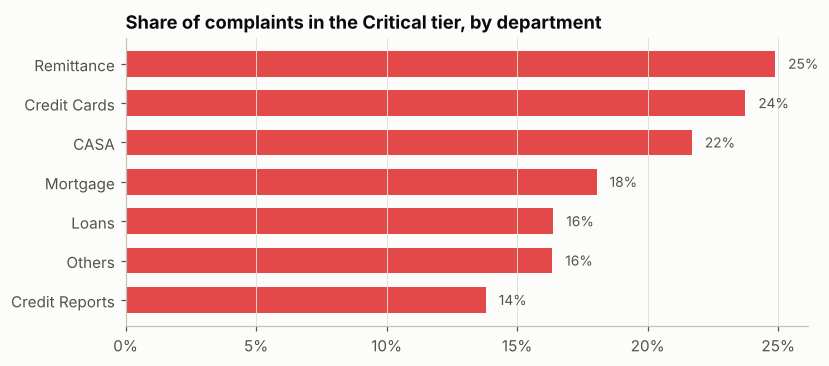

In [39]:
by_dept = (df.groupby("Department", observed=True)
             .agg(complaints=("Complaint ID", "size"),
                  mean_compound=("sent_compound", "mean"),
                  critical_share=("severity", lambda s: (s == "Critical").mean()),
                  monetary_relief=("Bank Response", lambda s: (s == "Closed with monetary relief").mean()))
             .sort_values("critical_share", ascending=False))
display(by_dept.style.format({"mean_compound": "{:+.3f}", "critical_share": "{:.1%}", "monetary_relief": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 3.4))
order = by_dept.sort_values("critical_share").index
ax.barh(order, by_dept.loc[order, "critical_share"], color=RED, height=0.65)
for i, d in enumerate(order):
    ax.text(by_dept.loc[d, "critical_share"] + 0.005, i, f"{by_dept.loc[d, 'critical_share']:.0%}",
            va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title("Share of complaints in the Critical tier, by department")
ax.grid(axis="y", visible=False)
save("08_critical_by_department")
plt.show()

### 5.3 Does sentiment line up with outcomes?

There's no labeled "true sentiment" to score VADER against, but there is an outcome: how the bank resolved the complaint. If more negative complaints more often end in **monetary relief** (meaning the bank agreed it owed the customer money), then the score is carrying real operational signal.

In [40]:
outcome = pd.crosstab(df["severity"], df["Bank Response"], normalize="index")
keep = ["Closed with explanation", "Closed with monetary relief", "Closed with non-monetary relief", "Untimely response"]
display(outcome[keep].style.format("{:.1%}"))

resp = (df.groupby("Bank Response", observed=True)
          .agg(complaints=("Complaint ID", "size"), mean_compound=("sent_compound", "mean"),
               critical_share=("severity", lambda s: (s == "Critical").mean()))
          .sort_values("mean_compound"))
display(resp.style.format({"mean_compound": "{:+.3f}", "critical_share": "{:.1%}"}))

df["monetary_relief"] = df["Bank Response"].eq("Closed with monetary relief")
relief = df.groupby("severity", observed=True)["monetary_relief"].mean()
print(f"Monetary-relief rate: Critical {relief['Critical']:.1%} vs Low/factual {relief['Low / factual']:.1%} "
      f"-> {relief['Critical']/relief['Low / factual']:.2f}x")

Bank Response,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief,Untimely response
severity,,,,
Critical,66.0%,25.1%,7.3%,1.1%
High,69.2%,18.3%,11.1%,0.6%
Moderate,72.2%,14.7%,11.8%,0.4%
Low / factual,71.0%,15.0%,13.1%,0.4%


,complaints,mean_compound,critical_share
Bank Response,,,
In progress,1,-0.945,0.0%
Untimely response,42,-0.675,35.7%
Closed with monetary relief,1251,-0.602,27.6%
Closed,51,-0.544,15.7%
Closed with explanation,4897,-0.523,18.5%
Closed with non-monetary relief,769,-0.486,13.0%


Monetary-relief rate: Critical 25.1% vs Low/factual 15.0% -> 1.67x


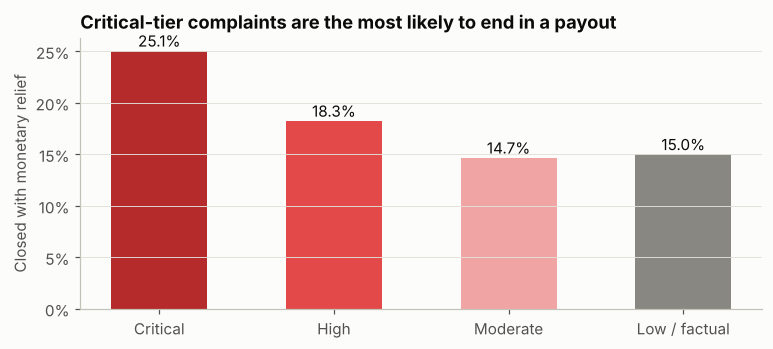

In [41]:
fig, ax = plt.subplots(figsize=(8, 3.2))
vals = [relief[t] for t in TIERS]
ax.bar(TIERS, vals, color=["#b52a2a", RED, "#f0a5a4", GRAY], width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + 0.004, f"{v:.1%}", ha="center", fontsize=10, color="#0b0b0b")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Closed with monetary relief")
ax.set_title("Critical-tier complaints are the most likely to end in a payout")
ax.grid(axis="x", visible=False)
save("09_relief_by_severity")
plt.show()

**Checking for confounders.** Longer complaints score more negative (more words, more negative hits), and longer complaints also tend to describe bigger, better-documented problems. Departments also differ a lot in payout rates: Credit Reports and Loans almost never pay out. So the raw gap above could just be length or department in disguise. Below, I hold those fixed in two ways: (1) relief rate by tier *within* complaint-length quartiles and within departments, and (2) a logistic regression of monetary relief on tier + log(length) + department.

In [42]:
df["length_quartile"] = pd.qcut(df["word_count"], 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])
by_len = df.pivot_table(index="length_quartile", columns="severity", values="monetary_relief", aggfunc="mean", observed=True)
by_len_n = df.pivot_table(index="length_quartile", columns="severity", values="monetary_relief", aggfunc="size", observed=True)
print("Monetary-relief rate by tier within length quartile (cells with < 30 complaints blanked):")
display(by_len.where(by_len_n >= 30).style.format("{:.1%}", na_rep="n<30"))

by_dept_tier = df.pivot_table(index="Department", columns="severity", values="monetary_relief", aggfunc="mean", observed=True)
print("Monetary-relief rate by tier within department:")
display(by_dept_tier.style.format("{:.1%}"))

Monetary-relief rate by tier within length quartile (cells with < 30 complaints blanked):


severity,Critical,High,Moderate,Low / factual
length_quartile,,,,
Q1 shortest,n<30,10.7%,9.7%,10.3%
Q2,18.4%,16.3%,15.3%,17.1%
Q3,22.0%,21.7%,20.6%,19.4%
Q4 longest,27.4%,20.6%,21.7%,19.7%


Monetary-relief rate by tier within department:


severity,Critical,High,Moderate,Low / factual
Department,,,,
CASA,35.9%,36.0%,28.6%,27.2%
Credit Cards,42.9%,28.7%,25.6%,18.8%
Credit Reports,3.3%,1.9%,2.4%,2.2%
Loans,1.6%,1.2%,1.9%,6.7%
Mortgage,8.5%,5.4%,7.0%,8.1%
Others,23.8%,21.9%,24.1%,32.2%
Remittance,20.0%,19.3%,9.4%,16.9%


In [43]:
X_or = pd.get_dummies(df[["Department"]], drop_first=True, dtype=float)
X_or["log_word_count"] = np.log(df["word_count"])
for t in ["Critical", "High", "Moderate"]:          # reference tier = Low / factual
    X_or[f"tier_{t}"] = (df["severity"] == t).astype(float)
logit = LogisticRegression(C=1e6, max_iter=5000).fit(X_or, df["monetary_relief"])
odds = pd.Series(np.exp(logit.coef_[0]), index=X_or.columns).round(2)
print("Odds ratios for monetary relief (reference: Low/factual tier, CASA department)")
odds[[c for c in odds.index if c.startswith("tier_")] + ["log_word_count"]].to_frame("odds ratio")

Odds ratios for monetary relief (reference: Low/factual tier, CASA department)


,odds ratio
tier_Critical,1.23
tier_High,1.10
tier_Moderate,1.01
log_word_count,1.30


### 5.4 What are customers actually complaining about? Topic model + sentiment

Departments are broad. To find the **underlying causes**, I run **NMF topic modeling** on a TF-IDF matrix of all cleaned complaints. This step is unsupervised, so fitting on the full corpus doesn't leak anything. Each complaint gets its dominant topic, and then sentiment, volume and payout rate are compared by topic.

In [44]:
N_TOPICS = 12
tfidf_topics = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, sublinear_tf=True, max_features=20000)
X_all = tfidf_topics.fit_transform(df["clean_text"])
nmf = NMF(n_components=N_TOPICS, init="nndsvda", random_state=RANDOM_STATE, max_iter=600)
W = nmf.fit_transform(X_all)
topic_terms = tfidf_topics.get_feature_names_out()
for k, comp in enumerate(nmf.components_):
    print(f"Topic {k:>2}: {', '.join(topic_terms[np.argsort(-comp)[:10]])}")

Topic  0: claim, transaction, fraud, charge, deny, debit, fraudulent, debit card, card, file
Topic  1: report, credit report, credit, remove, inquiry, bureau, credit bureau, remove credit, dispute, report credit
Topic  2: loan, mortgage, home, modification, payment, year, foreclosure, property, pay, interest
Topic  3: section, usc, usc section, consumer, right, section also, right privacy, consumer report, agency furnish, furnish account
Topic  4: card, credit card, credit, apply, bank credit, card bank, use, close, application, card account
Topic  5: call, get, tell, say, back, money, go, would, ask, phone
Topic  6: open, name, account open, open account, email, open name, close, bank account, fraud, social
Topic  7: check, deposit, fund, check account, hold, close, money, deposit check, cash, day
Topic  8: debt, collection, owe, collect, collection agency, company, agency, collector, pay, debt collector
Topic  9: identity, theft, identity theft, victim identity, victim, block, theft 

In [45]:
# Human-readable names, keyed on each topic's top term so they stay correct if topic order shifts
NAME_BY_TOP_TERM = {
    "claim": "Fraud claims & disputed transactions", "report": "Credit report errors & inquiries",
    "loan": "Mortgage servicing & modification", "section": "Legal / FCRA citation letters",
    "card": "Credit card accounts & applications", "call": "Customer-service runaround",
    "open": "Accounts opened in my name", "check": "Check deposits & fund holds",
    "debt": "Debt collection", "identity": "Identity theft reports",
    "payment": "Payments, late fees & charges", "provide": "Documentation & information requests",
}
TOPIC_NAMES = {}
for k, comp in enumerate(nmf.components_):
    top = topic_terms[np.argsort(-comp)[:3]]
    TOPIC_NAMES[k] = NAME_BY_TOP_TERM.get(top[0], ", ".join(top))
TOPIC_NAMES

{0: 'Fraud claims & disputed transactions',
 1: 'Credit report errors & inquiries',
 2: 'Mortgage servicing & modification',
 3: 'Legal / FCRA citation letters',
 4: 'Credit card accounts & applications',
 5: 'Customer-service runaround',
 6: 'Accounts opened in my name',
 7: 'Check deposits & fund holds',
 8: 'Debt collection',
 9: 'Identity theft reports',
 10: 'Payments, late fees & charges',
 11: 'Documentation & information requests'}

In [46]:
df["topic"] = pd.Categorical([TOPIC_NAMES[i] for i in W.argmax(axis=1)])
df["topic_strength"] = W.max(axis=1)

topics = (df.groupby("topic", observed=True)
            .agg(complaints=("Complaint ID", "size"),
                 mean_compound=("sent_compound", "mean"),
                 critical_share=("severity", lambda s: (s == "Critical").mean()),
                 monetary_relief=("Bank Response", lambda s: (s == "Closed with monetary relief").mean()),
                 main_department=("Department", lambda s: s.value_counts().index[0]))
            .sort_values("complaints", ascending=False))
topics.style.format({"mean_compound": "{:+.3f}", "critical_share": "{:.1%}", "monetary_relief": "{:.1%}"})

,complaints,mean_compound,critical_share,monetary_relief,main_department
topic,,,,,
Customer-service runaround,960,-0.607,27.7%,23.8%,CASA
Mortgage servicing & modification,805,-0.425,17.0%,4.8%,Mortgage
"Payments, late fees & charges",773,-0.447,13.6%,30.7%,Credit Cards
Credit card accounts & applications,755,-0.422,11.8%,19.6%,Credit Cards
Documentation & information requests,713,-0.599,25.9%,12.2%,Credit Reports
Check deposits & fund holds,634,-0.472,16.7%,32.0%,CASA
Fraud claims & disputed transactions,564,-0.769,39.2%,42.9%,CASA
Credit report errors & inquiries,552,-0.412,7.2%,1.3%,Credit Reports
Debt collection,515,-0.678,20.6%,1.6%,Loans


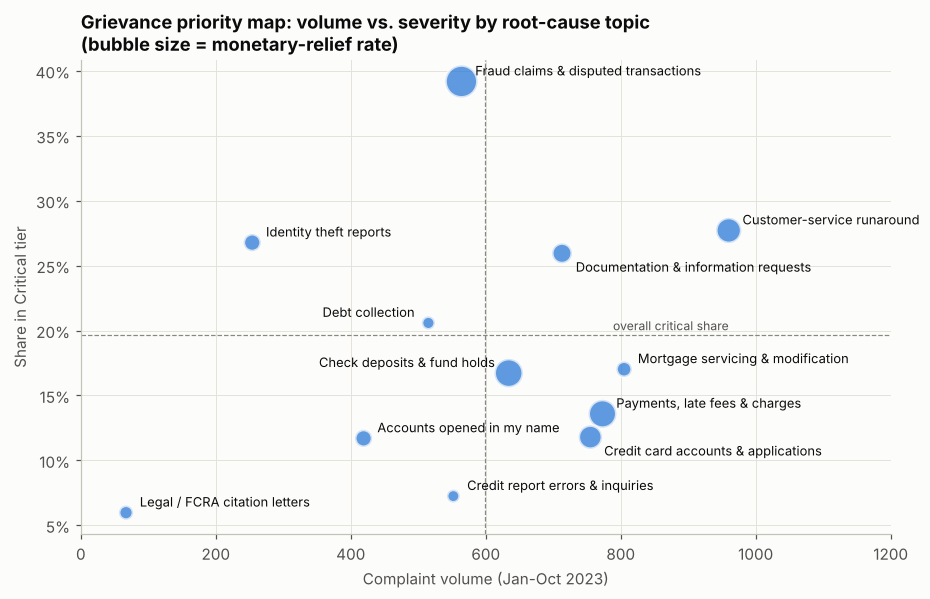

In [47]:
fig, ax = plt.subplots(figsize=(9.5, 5.6))
x, yv = topics["complaints"], topics["critical_share"]
sizes = 60 + 900 * topics["monetary_relief"]
ax.scatter(x, yv, s=sizes, color=BLUE, alpha=0.75, edgecolor="#fcfcfb", linewidth=2, zorder=3)
# a few labels go on the left / below so they don't collide
LEFT = {"Check deposits & fund holds", "Debt collection"}
BELOW = {"Credit card accounts & applications", "Documentation & information requests"}
for name, r in topics.iterrows():
    dx, ha = (-9, "right") if name in LEFT else (9, "left")
    dy = -12 if name in BELOW else 4
    ax.annotate(name, (r["complaints"], r["critical_share"]), xytext=(dx, dy), textcoords="offset points",
                fontsize=8.5, color="#0b0b0b", ha=ha)
ax.axhline(df["severity"].eq("Critical").mean(), color=GRAY, lw=0.8, ls="--")
ax.axvline(x.median(), color=GRAY, lw=0.8, ls="--")
ax.text(x.max(), df["severity"].eq("Critical").mean() + 0.004, "overall critical share", ha="right",
        fontsize=8, color="#52514e")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Complaint volume (Jan-Oct 2023)")
ax.set_ylabel("Share in Critical tier")
ax.set_title("Grievance priority map: volume vs. severity by root-cause topic\n(bubble size = monetary-relief rate)")
ax.set_xlim(0, x.max() * 1.25)
save("10_topic_priority_map")
plt.show()

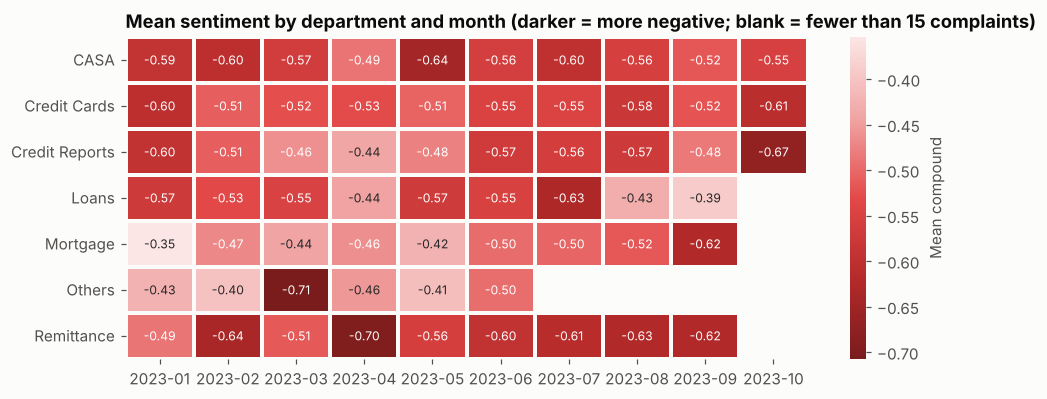

In [48]:
monthly_df = df.assign(month=df["Date Received"].dt.strftime("%Y-%m"))
heat = monthly_df.pivot_table(index="Department", columns="month", values="sent_compound", aggfunc="mean", observed=True)
heat_n = monthly_df.pivot_table(index="Department", columns="month", values="sent_compound", aggfunc="size", observed=True)
heat = heat.where(heat_n >= 15)          # hide cells with too few complaints to be meaningful
SEQ_RED = mpl.colors.LinearSegmentedColormap.from_list("seq_red", ["#7a1c1c", "#b52a2a", "#e34948", "#f0a5a4", "#fbe6e5"])
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(heat, cmap=SEQ_RED, annot=True, fmt="+.2f", annot_kws={"fontsize": 8},
            linewidths=1.5, linecolor="#fcfcfb", cbar_kws={"label": "Mean compound"}, ax=ax)
ax.set_title("Mean sentiment by department and month (darker = more negative; blank = fewer than 15 complaints)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.grid(False)
save("11_sentiment_heatmap")
plt.show()

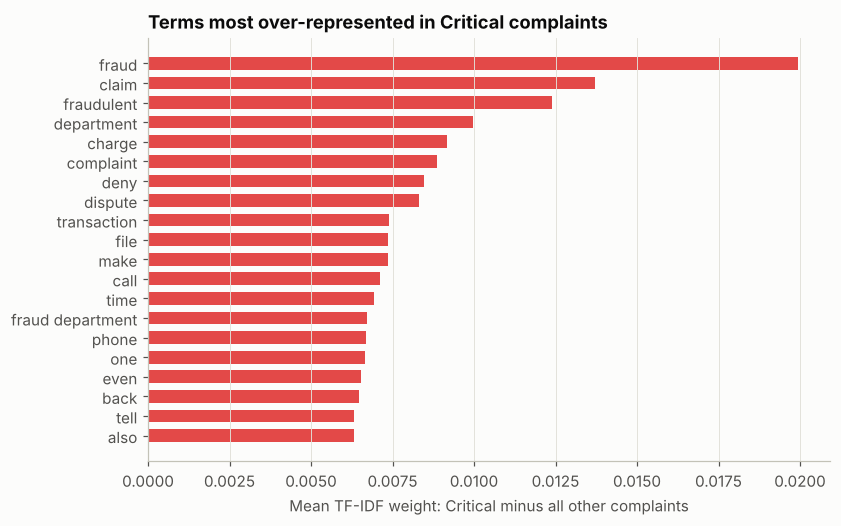

In [49]:
# Words that most distinguish Critical complaints from the rest (difference in mean TF-IDF weight)
critical_mask = (df["severity"] == "Critical").values
diff = np.asarray(X_all[critical_mask].mean(axis=0)).ravel() - np.asarray(X_all[~critical_mask].mean(axis=0)).ravel()
top_idx = np.argsort(-diff)[:20]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(topic_terms[top_idx][::-1], diff[top_idx][::-1], color=RED, height=0.65)
ax.set_title("Terms most over-represented in Critical complaints")
ax.set_xlabel("Mean TF-IDF weight: Critical minus all other complaints")
ax.grid(axis="y", visible=False)
save("12_critical_terms")
plt.show()

In [50]:
# Issue IDs (the bank's internal issue codes) with the most negative complaints, min 40 complaints
issues = (df.groupby("Issue ID", observed=True)
            .agg(complaints=("Complaint ID", "size"), mean_compound=("sent_compound", "mean"),
                 critical_share=("severity", lambda s: (s == "Critical").mean()),
                 department=("Department", lambda s: s.value_counts().index[0]),
                 top_topic=("topic", lambda s: s.value_counts().index[0]))
            .query("complaints >= 40").sort_values("critical_share", ascending=False).head(10))
issues.style.format({"mean_compound": "{:+.3f}", "critical_share": "{:.1%}"})

,complaints,mean_compound,critical_share,department,top_topic
Issue ID,,,,,
I_2292291,319,-0.777,47.3%,Credit Cards,Credit card accounts & applications
I_9017186,124,-0.753,38.7%,Credit Cards,Fraud claims & disputed transactions
I_2805744,67,-0.690,37.3%,Credit Cards,Fraud claims & disputed transactions
I_5455278,61,-0.731,34.4%,Loans,Debt collection
I_1514870,277,-0.649,28.9%,Remittance,Customer-service runaround
I_4921263,111,-0.517,27.9%,Mortgage,Mortgage servicing & modification
I_2611782,203,-0.659,27.1%,CASA,Fraud claims & disputed transactions
I_5604143,56,-0.571,26.8%,Credit Cards,"Payments, late fees & charges"
I_5155996,40,-0.461,25.0%,Mortgage,Mortgage servicing & modification


In [51]:
# Save the scored complaints for dashboards / the transformer notebook (no free text, just keys and scores)
cols = ["Complaint ID", "Date Received", "Department", "Banking Product", "Issue ID", "State", "Bank Response",
        "vader_compound", "sent_neg", "sent_neu", "sent_pos", "sent_compound", "sent_label", "severity", "topic"]
df[cols].to_csv(OUT_DIR / "complaints_scored.csv", index=False)
print("Saved", OUT_DIR / "complaints_scored.csv", df[cols].shape)

Saved outputs/complaints_scored.csv (7011, 15)


### 5.5 Sentiment findings: what is driving the grievances?

* **Domain adjustment matters.** Out-of-the-box VADER calls **41%** of these complaints *positive*, mostly because *credit*, *interest* and polite phrases ("please help") read as positive. After neutralizing 56 banking and politeness terms, **80%** score negative and 12% positive. The remaining positives are mostly long, calm, factual write-ups.
* **Departments:** **Remittance** has the highest share of Critical-tier complaints (24.9%), followed by **Credit Cards** (23.7%) and **CASA** (21.7%). **Credit Reports** has the lowest (13.8%) because so many of its complaints are templated dispute letters.
* **Root causes (topic model):**
  * **Fraud claims & disputed transactions** is the most intense grievance: mean compound -0.77, **39% Critical**, and the **highest monetary-relief rate (43%)**. Customers are angriest where the bank most often ends up paying.
  * **Customer-service runaround** (*call, tell, say, back, phone*) is the **largest topic (960 complaints)** and the second most intense (28% Critical). Being bounced between agents makes people angrier than the original problem does.
  * **Identity theft** (27% Critical) and **documentation requests** (26% Critical) are also above average.
  * **Payments/late fees** and **check deposits/fund holds** are *moderate* in tone but pay out often (31-32%). These are rule-driven problems, and fixing the rule would be cheaper than paying them out one complaint at a time.
  * **Debt collection** is intense (21% Critical) but almost never pays out (1.6%), so the lever there is communication and conduct, not money.
* **Critical-tier vocabulary** is dominated by *fraud, claim, fraudulent, deny, dispute* and by contact friction: *department, call, phone, back, tell, time*.
* **Sentiment vs. outcomes:** Critical complaints end in monetary relief **25%** of the time vs **15%** for Low/factual (1.7x). Part of that gap is because angry complaints are also longer. After controlling for length and department, Critical complaints still have **about 1.23x the odds** of a payout. The effect is concentrated in **Credit Cards** (43% vs 19%) and **CASA** (36% vs 27%), and is essentially absent in Credit Reports, Loans and Mortgage, where payouts are rare in any tier.
* **Late responses hit the angriest customers:** the 42 complaints the bank answered late have the most negative mean score of any outcome (-0.68) and a 36% Critical share, nearly double the overall rate.

## 6. Transformer-based modeling → `02_transformer_models.ipynb`

The transformer work lives in its own notebook because it needs a GPU and downloads pretrained weights from Hugging Face. That notebook:
1. **Fine-tunes DistilBERT** to predict Department, using the exact train/test split saved here (`outputs/split_ids.csv`), and compares it head-to-head with the TF-IDF model (`outputs/tfidf_metrics.json`).
2. Runs a **pretrained transformer sentiment model** over the same complaints and measures how far it agrees with VADER, as an independent check on the Section 5 sentiment scores.

**Results:** DistilBERT reached **macro-F1 0.767 vs 0.734** for TF-IDF (accuracy 78.9% vs 78.8%). The gain is concentrated in **Others (F1 0.40 → 0.68)** and CASA, while TF-IDF stays slightly ahead on Mortgage, Loans and Credit Reports. The RoBERTa sentiment model labeled **70% of complaints negative and essentially none positive**. That confirms out-of-the-box VADER's 41% "positive" was a lexicon artifact, but RoBERTa's complaint-by-complaint ranking agreed only weakly with VADER (Spearman ρ 0.10-0.22). Section 7.3 covers what that means for the severity tiers.

## 7. Business insights & strategy recommendations for Retail Banking

### 7.1 How the bank can use the sentiment score

The compound score works best as a **severity signal attached to every complaint at intake**, read alongside the predicted department. It isn't a verdict on whether the customer is right. Concrete uses:

| Use | How it works | Evidence from this analysis |
|---|---|---|
| **Priority queue** | Sort each department's queue by severity tier and give Critical complaints a shorter internal SLA and a senior handler. | Critical ≈ 20% of volume; late responses are concentrated among the most negative complaints (36% Critical vs ~20% overall). |
| **Early payout and remediation flag** | In Credit Cards and CASA, flag Critical complaints for an early look at remediation, before the customer escalates further. | Within Credit Cards, 43% of Critical complaints end in monetary relief vs 19% of Low/factual. |
| **Root-cause dashboard** | Track volume × Critical share by topic and by internal Issue ID each month (Sections 5.4 and 5.5). | Fraud-claim and service-runaround topics stand out; Issue **I_2292291** (Credit Cards, 319 complaints, 47% Critical) is the single worst issue code. |
| **Early-warning alerts** | Alert when a department's monthly mean sentiment or Critical share moves well outside its usual range. | Mortgage sentiment drifted from about -0.35 in January to -0.62 in September, the kind of shift an alert would catch weeks before it shows up in volume. |
| **Agent coaching & QA** | Use the most negative complaints, and the words that drive them, as training material. | Critical vocabulary is full of contact friction: *call, phone, back, tell, department*. |
| **Regulatory risk monitoring** | Combine Critical tier with fraud / identity-theft topics to spot complaints most likely to turn into regulatory findings. | Fraud and identity-theft topics have the highest Critical shares. |

### 7.2 Recommended strategies

1. **Automate first-line triage (Section 4.1).** Auto-route complaints where the classifier is at least 70% confident (about half the volume, at 91% accuracy) and send the rest to the manual triage team. Start in shadow mode next to the current process, then raise or lower the threshold based on the team's capacity.
2. **Fix the fraud-claim process first.** It's the most negative topic *and* the one with the highest payout rate (43%), which means the bank often ends up paying anyway after an angry escalation. Review denial criteria, explain investigation results clearly, extend provisional credit where it's appropriate, and keep a close eye on Regulation E error-resolution timelines.
3. **Make "one owner per complaint" the rule.** The largest topic is customer-service runaround. Giving each complaint a named case owner, a committed callback time and a single reference number goes straight at the biggest driver of Critical-tier language.
4. **Scam prevention for Remittance.** Remittance has the highest Critical share, and its vocabulary is *scam, scammer, wire*. Add stronger in-app warnings before first-time transfers, faster recall attempts, and clear guidance on what can and can't be recovered.
5. **Fix the rules behind fees and fund holds.** Late-fee and check-hold complaints pay out about 31-32% of the time while staying fairly calm. Clearer hold notices, a one-time fee-waiver policy and proactive notifications would cut volume more cheaply than handling each one as a complaint.
6. **Clean up the product taxonomy.** Retire the legacy *Others / Bank account or service* label in favor of CASA. That simplifies routing and lifts classifier accuracy from 78.8% to about 80.7% with no model changes.

### 7.3 Caveats and guardrails
* **VADER is lexicon-based, and the transformer check only partly backs it up.** RoBERTa (notebook 02) agrees that these complaints are overwhelmingly negative and essentially never positive, but it ranks individual complaints quite differently (Spearman ρ 0.10 with domain-adjusted VADER). So the severity tiers here are a **coarse flag, not a precise ranking**, and the topic and department comparisons in Section 5 should be re-checked against the transformer score (`outputs/transformer_sentiment.csv`) before anyone acts on them. Before tiers drive SLAs, hand-label a sample of a few hundred complaints, see which score matches human judgment better, and consider switching the tier score to the transformer's negative-class probability, which doesn't saturate on long texts.
* **Calm doesn't mean less valid.** Low/factual complaints still end in monetary relief 15% of the time. Sentiment should move complaints *up* the queue. It should **never** be used to deprioritize or deny a calm, formal writer, since that would penalize customers who write formally or in a second language.
* **These are associations, not causes.** The outcome analysis controls for length and department but not for complaint merit, which isn't in the data.
* **The data covers about 10 months of 2023.** The models and lexicon adjustments should be retrained or reviewed regularly as products, scams and the taxonomy change.